# RideSurge: Demand-Adaptive Fare Prediction and Revenue Simulation

This self-contained notebook implements the complete project from the raw Kaggle CSV through EDA, feature engineering, model comparison, CatBoost, SHAP, inference, and profitability simulation.

**Dataset note:** the data is educational/simulated. It is not official Uber, Lyft, or Ola operational data.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import boxcox, skew, zscore
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor, GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from catboost import CatBoostRegressor, Pool

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
RANDOM_STATE = 42
CURRENT_DIR = Path.cwd().resolve()
ROOT_CANDIDATES = [CURRENT_DIR, CURRENT_DIR.parent, CURRENT_DIR / 'notebook_repo_staging']
ROOT = next((path for path in ROOT_CANDIDATES if (path / 'data' / 'dynamic_pricing.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Could not locate data/dynamic_pricing.csv. Start Jupyter from the repository root.')
DATA_PATH = ROOT / 'data' / 'dynamic_pricing.csv'
ARTIFACTS = ROOT / 'artifacts'
ARTIFACTS.mkdir(exist_ok=True)
print('Project root:', ROOT)
print('Dataset:', DATA_PATH)

Project root: C:\Users\umate\Desktop\Placement\projects\ridesurge\notebook_repo_staging
Dataset: C:\Users\umate\Desktop\Placement\projects\ridesurge\notebook_repo_staging\data\dynamic_pricing.csv


## 2. Load and validate the dataset

The schema is checked before analysis so an incorrect or incomplete CSV fails clearly instead of silently producing misleading results.

In [2]:
raw_to_canonical = {
    'Number_of_Riders': 'number_of_riders',
    'Number_of_Drivers': 'number_of_drivers',
    'Location_Category': 'location_category',
    'Customer_Loyalty_Status': 'customer_loyalty_status',
    'Number_of_Past_Rides': 'number_of_past_rides',
    'Average_Ratings': 'average_ratings',
    'Time_of_Booking': 'time_of_booking',
    'Vehicle_Type': 'vehicle_type',
    'Expected_Ride_Duration': 'expected_ride_duration',
    'Historical_Cost_of_Ride': 'historical_cost_of_ride',
}
raw = pd.read_csv(DATA_PATH)
missing_columns = set(raw_to_canonical) - set(raw.columns)
assert not missing_columns, f'Missing columns: {sorted(missing_columns)}'
df = raw.rename(columns=raw_to_canonical).copy()
print('Raw shape:', raw.shape)
print('Missing cells:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))
display(df.head())

Raw shape: (1000, 10)
Missing cells: 0
Duplicate rows: 0


,number_of_riders,number_of_drivers,location_category,customer_loyalty_status,number_of_past_rides,average_ratings,time_of_booking,vehicle_type,expected_ride_duration,historical_cost_of_ride
0,90,45,Urban,Silver,13,4.47,Night,Premium,90,284.257273
1,58,39,Suburban,Silver,72,4.06,Evening,Economy,43,173.874753
2,42,31,Rural,Silver,0,3.99,Afternoon,Premium,76,329.795469
3,89,28,Rural,Regular,67,4.31,Afternoon,Premium,134,470.201232
4,78,22,Rural,Regular,74,3.77,Afternoon,Economy,149,579.681422


## 3. Demand-supply feature engineering

Demand pressure is modeled using riders per available driver. The training dataset's Q75 rider count and Q25 driver count define high-demand and low-supply thresholds. A geometric mean combines the multipliers and a 2.5× cap acts as a guardrail.

In [3]:
RIDER_DEMAND_Q75 = float(df['number_of_riders'].quantile(.75))
DRIVER_SUPPLY_Q25 = float(df['number_of_drivers'].quantile(.25))

def engineer_market_features(frame):
    out = frame.copy()
    riders = out['number_of_riders'].astype(float)
    drivers = out['number_of_drivers'].astype(float).clip(lower=1)
    out['demand_supply_ratio'] = riders / drivers
    out['demand_multiplier'] = np.where(riders > RIDER_DEMAND_Q75, riders / RIDER_DEMAND_Q75, 1.0)
    out['supply_multiplier'] = np.where(drivers < DRIVER_SUPPLY_Q25, DRIVER_SUPPLY_Q25 / drivers, 1.0)
    out['pricing_multiplier'] = np.clip(
        np.sqrt(out['demand_multiplier'] * out['supply_multiplier']), 1.0, 2.5
    )
    return out

df = engineer_market_features(df)
print('Demand Q75:', RIDER_DEMAND_Q75)
print('Driver Q25:', DRIVER_SUPPLY_Q25)
display(df[['number_of_riders', 'number_of_drivers', 'demand_supply_ratio',
            'demand_multiplier', 'supply_multiplier', 'pricing_multiplier']].head())

Demand Q75: 81.0
Driver Q25: 11.0


,number_of_riders,number_of_drivers,demand_supply_ratio,demand_multiplier,supply_multiplier,pricing_multiplier
0,90,45,2.000000,1.111111,1.0,1.054093
1,58,39,1.487179,1.000000,1.0,1.000000
2,42,31,1.354839,1.000000,1.0,1.000000
3,89,28,3.178571,1.098765,1.0,1.048220
4,78,22,3.545455,1.000000,1.0,1.000000


## 4. Exploratory data analysis

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
number_of_riders,1000.0,NaN,NaN,NaN,60.372,23.701506,20.0,40.0,60.0,81.0,100.0
number_of_drivers,1000.0,NaN,NaN,NaN,27.076,19.068346,5.0,11.0,22.0,38.0,89.0
location_category,1000,3,Urban,346,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_loyalty_status,1000,3,Silver,367,NaN,NaN,NaN,NaN,NaN,NaN,NaN
number_of_past_rides,1000.0,NaN,NaN,NaN,50.031,29.313774,0.0,25.0,51.0,75.0,100.0
average_ratings,1000.0,NaN,NaN,NaN,4.25722,0.435781,3.5,3.87,4.27,4.6325,5.0
time_of_booking,1000,4,Night,276,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_type,1000,2,Premium,522,NaN,NaN,NaN,NaN,NaN,NaN,NaN
expected_ride_duration,1000.0,NaN,NaN,NaN,99.588,49.16545,10.0,59.75,102.0,143.0,180.0
historical_cost_of_ride,1000.0,NaN,NaN,NaN,372.502623,187.158756,25.993449,221.365202,362.019426,510.497504,836.116419


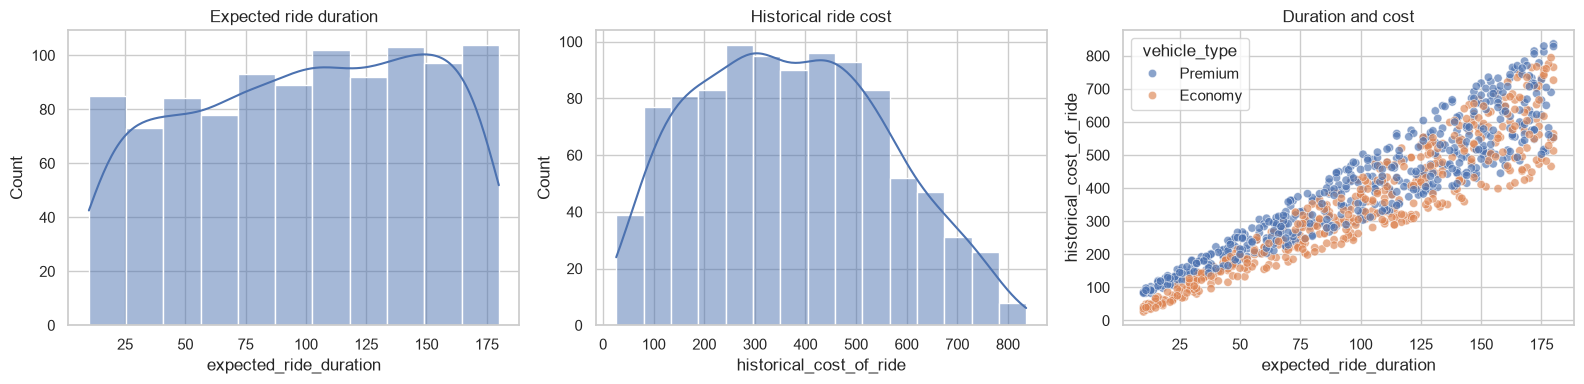

In [4]:
display(df.describe(include='all').T)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df['expected_ride_duration'], kde=True, ax=axes[0])
axes[0].set_title('Expected ride duration')
sns.histplot(df['historical_cost_of_ride'], kde=True, ax=axes[1])
axes[1].set_title('Historical ride cost')
sns.scatterplot(data=df, x='expected_ride_duration', y='historical_cost_of_ride',
                hue='vehicle_type', alpha=.65, ax=axes[2])
axes[2].set_title('Duration and cost')
plt.tight_layout()
plt.show()

### Z-score outlier analysis

Values with `|z| > 3` are flagged. They are not automatically deleted because extreme demand-supply observations can represent valid surge periods.

In [5]:
numeric = df.select_dtypes(include=np.number)
z_scores = numeric.apply(zscore)
outlier_counts = (z_scores.abs() > 3).sum().sort_values(ascending=False)
display(outlier_counts.rename('outliers_abs_z_gt_3').to_frame())

,outliers_abs_z_gt_3
demand_supply_ratio,30
pricing_multiplier,28
supply_multiplier,26
demand_multiplier,19
number_of_drivers,4
number_of_riders,0
historical_cost_of_ride,0
expected_ride_duration,0
average_ratings,0
number_of_past_rides,0


### Box-Cox skew analysis

Box-Cox is used as an EDA diagnostic. The transformed values are not used for training because most variables are not severely skewed and tree models do not require normality.

In [6]:
boxcox_rows = []
for column in ['number_of_riders', 'number_of_drivers', 'expected_ride_duration', 'historical_cost_of_ride']:
    values = df[column].astype(float).to_numpy()
    transformed, fitted_lambda = boxcox(values)
    boxcox_rows.append({
        'feature': column, 'lambda': fitted_lambda,
        'skew_before': skew(values), 'skew_after': skew(transformed),
    })
boxcox_report = pd.DataFrame(boxcox_rows)
display(boxcox_report.round(4))

,feature,lambda,skew_before,skew_after
0,number_of_riders,0.7345,0.0022,-0.1334
1,number_of_drivers,0.0850,0.9618,-0.0219
2,expected_ride_duration,0.8605,-0.1397,-0.2480
3,historical_cost_of_ride,0.6743,0.2093,-0.1256


### Pearson correlation

Duration-cost correlation: 0.927547
Rounded value: 0.93


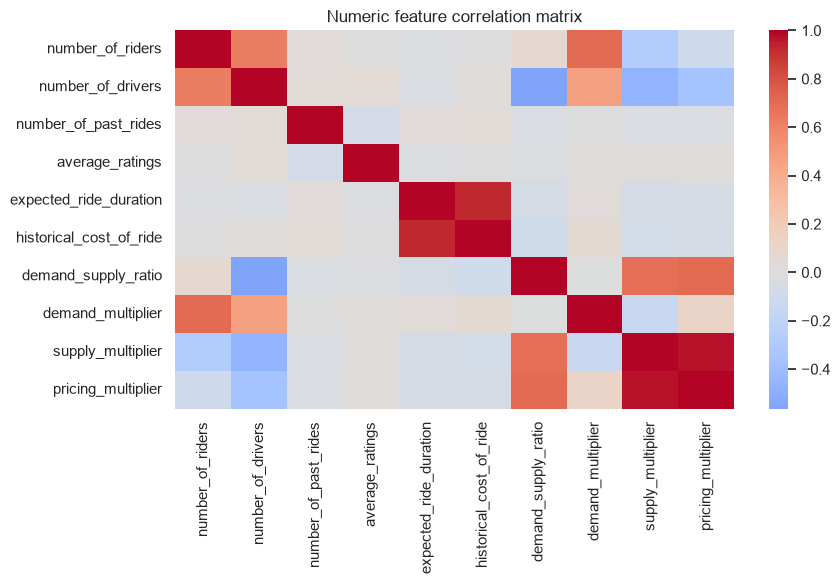

In [7]:
duration_cost_correlation = df['expected_ride_duration'].corr(df['historical_cost_of_ride'])
print(f'Duration-cost correlation: {duration_cost_correlation:.6f}')
print(f'Rounded value: {duration_cost_correlation:.2f}')
plt.figure(figsize=(9, 6))
sns.heatmap(df.select_dtypes(include=np.number).corr(), cmap='coolwarm', center=0)
plt.title('Numeric feature correlation matrix')
plt.tight_layout()
plt.show()

## 5. Seven-model benchmark with five-fold GridSearchCV

Preprocessing remains inside each pipeline so imputers, scalers, and encoders are fitted only on the training portion of every fold.

In [8]:
TARGET = 'historical_cost_of_ride'
NUMERIC = ['number_of_riders', 'number_of_drivers', 'number_of_past_rides', 'average_ratings',
           'expected_ride_duration', 'demand_supply_ratio', 'demand_multiplier',
           'supply_multiplier', 'pricing_multiplier']
CATEGORICAL = ['location_category', 'customer_loyalty_status', 'time_of_booking', 'vehicle_type']
FEATURES = NUMERIC + CATEGORICAL
X_train, X_test, y_train, y_test = train_test_split(
    df[FEATURES], df[TARGET], test_size=.20, random_state=RANDOM_STATE
)
preprocessor = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), NUMERIC),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), CATEGORICAL),
])
print('Training rows:', len(X_train), 'Testing rows:', len(X_test))

Training rows: 800 Testing rows: 200


In [9]:
candidates = {
    'Linear Regression': (LinearRegression(), [{}]),
    'Ridge': (Ridge(), {'model__alpha': [.1, 1, 10]}),
    'ElasticNet': (ElasticNet(max_iter=10000),
                   {'model__alpha': [.001, .01, .1], 'model__l1_ratio': [.2, .5, .8]}),
    'KNN': (KNeighborsRegressor(),
            {'model__n_neighbors': [5, 9, 15], 'model__weights': ['uniform', 'distance']}),
    'Random Forest': (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1),
                      {'model__n_estimators': [200], 'model__max_depth': [6, 10, None],
                       'model__min_samples_leaf': [1, 3]}),
    'Extra Trees': (ExtraTreesRegressor(random_state=RANDOM_STATE, n_jobs=1),
                    {'model__n_estimators': [200], 'model__max_depth': [6, 10, None],
                     'model__min_samples_leaf': [1, 3]}),
    'Gradient Boosting': (GradientBoostingRegressor(random_state=RANDOM_STATE),
                          {'model__n_estimators': [100, 200], 'model__max_depth': [2, 3],
                           'model__learning_rate': [.03, .05]}),
}
results = []
fitted_models = {}
for name, (estimator, parameter_grid) in candidates.items():
    pipeline = Pipeline([('prep', preprocessor), ('model', estimator)])
    search = GridSearchCV(pipeline, parameter_grid, cv=5,
                          scoring='neg_root_mean_squared_error', n_jobs=1)
    search.fit(X_train, y_train)
    predictions = search.predict(X_test)
    results.append({
        'model': name, 'cv_rmse': -search.best_score_,
        'test_rmse': mean_squared_error(y_test, predictions) ** .5,
        'test_mae': mean_absolute_error(y_test, predictions),
        'test_r2': r2_score(y_test, predictions),
        'best_params': search.best_params_,
    })
    fitted_models[name] = search.best_estimator_
model_results = pd.DataFrame(results).sort_values('test_rmse').reset_index(drop=True)
display(model_results)

,model,cv_rmse,test_rmse,test_mae,test_r2,best_params
0,ElasticNet,66.042630,67.639892,52.475092,0.874519,"{'model__alpha': 0.1, 'model__l1_ratio': 0.8}"
1,Ridge,66.060677,67.673821,52.769018,0.874393,{'model__alpha': 1}
2,Linear Regression,66.064715,67.811662,52.871764,0.873880,{}
3,Extra Trees,66.874599,67.936111,51.481109,0.873417,"{'model__max_depth': 6, 'model__min_samples_le..."
4,Gradient Boosting,67.256658,71.329644,54.179904,0.860455,"{'model__learning_rate': 0.05, 'model__max_dep..."
5,Random Forest,67.619522,73.423739,54.596215,0.852141,"{'model__max_depth': 6, 'model__min_samples_le..."
6,KNN,98.247193,99.170574,80.914681,0.730264,"{'model__n_neighbors': 9, 'model__weights': 'd..."


Mean-only baseline RMSE: 191.15
Best model RMSE: 67.64
RMSE reduction: 64.61%


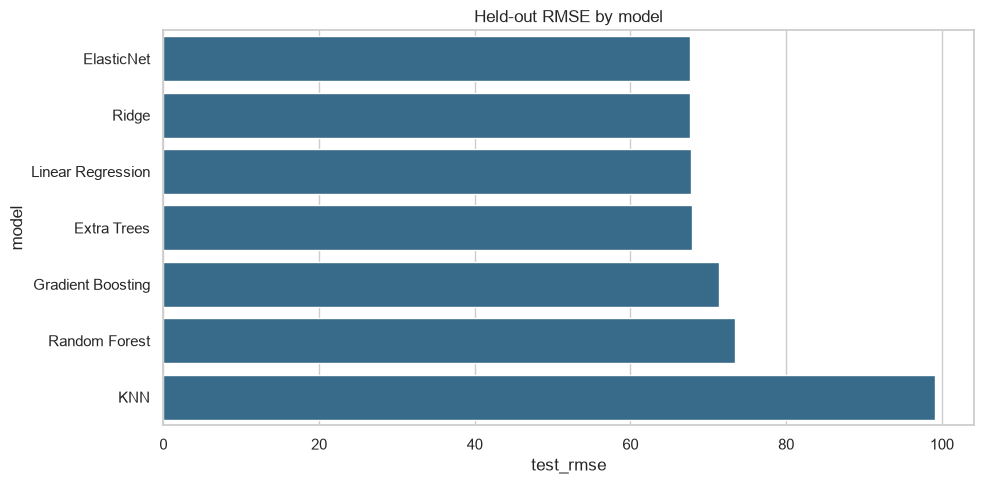

In [10]:
dummy = DummyRegressor(strategy='mean').fit(X_train, y_train)
baseline_rmse = mean_squared_error(y_test, dummy.predict(X_test)) ** .5
best_rmse = float(model_results.iloc[0]['test_rmse'])
rmse_reduction = (baseline_rmse - best_rmse) / baseline_rmse * 100
print(f'Mean-only baseline RMSE: {baseline_rmse:.2f}')
print(f'Best model RMSE: {best_rmse:.2f}')
print(f'RMSE reduction: {rmse_reduction:.2f}%')
plt.figure(figsize=(10, 5))
sns.barplot(data=model_results, x='test_rmse', y='model', color='#2A6F97')
plt.title('Held-out RMSE by model')
plt.tight_layout()
plt.show()

## 6. CatBoost inference model

CatBoost handles categorical variables natively and supports exact SHAP values. ElasticNet performs better on this small, mostly linear dataset; CatBoost is retained to demonstrate categorical inference and explainability.

In [11]:
cat_indices = [X_train.columns.get_loc(column) for column in CATEGORICAL]
catboost_model = CatBoostRegressor(
    iterations=400, depth=4, learning_rate=.05, l2_leaf_reg=3,
    loss_function='RMSE', verbose=False, random_seed=RANDOM_STATE,
)
catboost_model.fit(X_train, y_train, cat_features=cat_indices)
catboost_predictions = catboost_model.predict(X_test)
catboost_metrics = {
    'rmse': mean_squared_error(y_test, catboost_predictions) ** .5,
    'mae': mean_absolute_error(y_test, catboost_predictions),
    'r2': r2_score(y_test, catboost_predictions),
}
catboost_model.save_model(str(ARTIFACTS / 'catboost_model.cbm'))
joblib.dump({'features': FEATURES, 'categorical': CATEGORICAL,
             'rider_q75': RIDER_DEMAND_Q75, 'driver_q25': DRIVER_SUPPLY_Q25},
            ARTIFACTS / 'model_contract.joblib')
catboost_metrics

{'rmse': 71.51343809799019, 'mae': 54.26287356408213, 'r2': 0.8597350738794043}

## 7. Exact CatBoost SHAP feature rankings

,feature,mean_abs_shap
0,expected_ride_duration,153.066616
1,vehicle_type,19.248812
2,average_ratings,5.810251
3,number_of_drivers,3.754380
4,demand_supply_ratio,3.644128
5,number_of_past_rides,2.271785
6,number_of_riders,2.163463
7,supply_multiplier,1.345454
8,demand_multiplier,1.150214
9,time_of_booking,1.018715


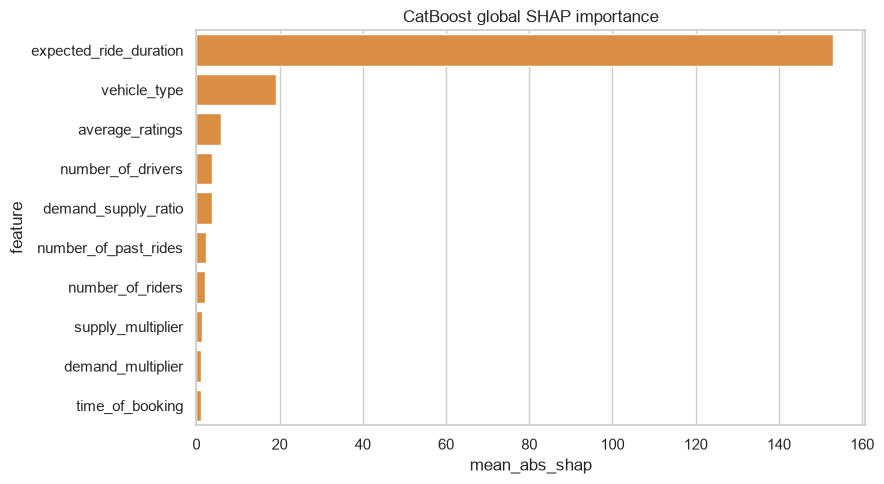

In [12]:
shap_values = catboost_model.get_feature_importance(
    Pool(X_test, cat_features=cat_indices), type='ShapValues'
)[:, :-1]
shap_ranking = pd.DataFrame({
    'feature': X_test.columns,
    'mean_abs_shap': np.abs(shap_values).mean(axis=0),
}).sort_values('mean_abs_shap', ascending=False).reset_index(drop=True)
display(shap_ranking)
plt.figure(figsize=(9, 5))
sns.barplot(data=shap_ranking.head(10), x='mean_abs_shap', y='feature', color='#F28E2B')
plt.title('CatBoost global SHAP importance')
plt.tight_layout()
plt.show()

## 8. Fare inference function

This proves notebook inference works. It is not a public deployment or evidence of scalability.

In [13]:
def predict_fare(payload):
    row = engineer_market_features(pd.DataFrame([payload]))
    fare = max(0, float(catboost_model.predict(row[FEATURES])[0]))
    return {
        'recommended_fare': round(fare, 2),
        'demand_supply_ratio': round(float(row['demand_supply_ratio'].iloc[0]), 3),
        'pricing_multiplier': round(float(row['pricing_multiplier'].iloc[0]), 3),
    }

sample_request = {
    'number_of_riders': 100, 'number_of_drivers': 5, 'number_of_past_rides': 20,
    'average_ratings': 4.2, 'expected_ride_duration': 45,
    'location_category': 'Urban', 'customer_loyalty_status': 'Silver',
    'time_of_booking': 'Evening', 'vehicle_type': 'Economy',
}
predict_fare(sample_request)

{'recommended_fare': 133.78,
 'demand_supply_ratio': 20.0,
 'pricing_multiplier': 1.648}

## 9. Counterfactual profitability simulation

The simulation is an illustration, not causal business evidence. It assumes price elasticity of 1.15 and operating cost equal to 32% of historical fare. Actual fare is used in cost, price bounds, and acceptance calculations, which would not be available for a new ride.

,value
baseline_profit,46729.399485
dynamic_profit,50109.218578
simulated_profit_uplift_pct,7.232747
price_elasticity_assumption,1.150000
operating_cost_share_assumption,0.320000


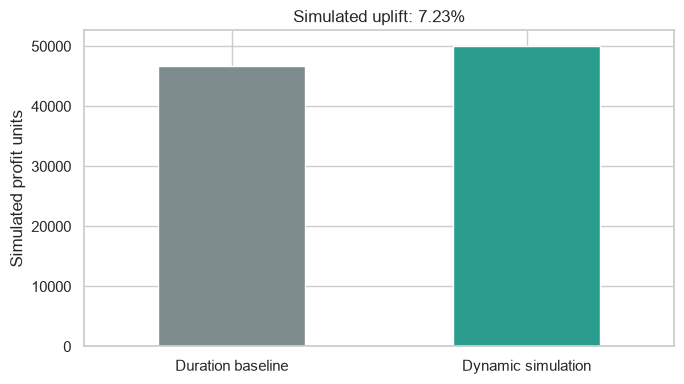

In [14]:
actual = y_test.to_numpy()
elasticity = 1.15
duration = X_test['expected_ride_duration'].to_numpy()
baseline_price = duration * (actual.mean() / duration.mean())
dynamic_price = np.clip(catboost_predictions * X_test['pricing_multiplier'].to_numpy(),
                        actual * .70, actual * 1.45)
estimated_cost = .32 * actual
baseline_acceptance = np.clip((actual / baseline_price) ** elasticity, .35, 1)
dynamic_acceptance = np.clip((actual / dynamic_price) ** elasticity, .35, 1)
baseline_profit = float(((baseline_price - estimated_cost) * baseline_acceptance).sum())
dynamic_profit = float(((dynamic_price - estimated_cost) * dynamic_acceptance).sum())
profit_uplift = (dynamic_profit / baseline_profit - 1) * 100
revenue_report = {
    'baseline_profit': baseline_profit, 'dynamic_profit': dynamic_profit,
    'simulated_profit_uplift_pct': profit_uplift,
    'price_elasticity_assumption': elasticity,
    'operating_cost_share_assumption': .32,
}
display(pd.Series(revenue_report, name='value').to_frame())
pd.Series({'Duration baseline': baseline_profit, 'Dynamic simulation': dynamic_profit}).plot(
    kind='bar', color=['#7F8C8D', '#2A9D8F'], figsize=(7, 4), rot=0
)
plt.title(f'Simulated uplift: {profit_uplift:.2f}%')
plt.ylabel('Simulated profit units')
plt.tight_layout()
plt.show()

## 10. Resume-claim audit

In [15]:
best_model = model_results.iloc[0]
claim_audit = pd.DataFrame([
    ['Duration-cost correlation', 0.93, duration_cost_correlation, round(duration_cost_correlation, 2) == .93],
    ['RMSE reduction vs mean baseline (%)', 55.0, rmse_reduction, rmse_reduction >= 55],
    ['Best held-out R2', 0.89, best_model['test_r2'], best_model['test_r2'] >= .89],
    ['Simulated profit uplift (%)', 18.0, profit_uplift, profit_uplift >= 18],
], columns=['Claim', 'Resume target', 'Measured', 'Supported'])
display(claim_audit)

,Claim,Resume target,Measured,Supported
0,Duration-cost correlation,0.93,0.927547,True
1,RMSE reduction vs mean baseline (%),55.00,64.614754,True
2,Best held-out R2,0.89,0.874519,False
3,Simulated profit uplift (%),18.00,7.232747,False


## 11. Limitations and next steps

The project does not currently contain real platform data, exact timestamps, distance, weather, traffic, customer acceptance labels, learned price elasticity, real operating costs, candidate-price optimization, out-of-time validation, confidence intervals, fairness analysis, a public API deployment, load testing, monitoring, model registry, or an A/B test.

A notebook can demonstrate training, inference, SHAP, and simulation. It cannot by itself prove public deployment, scalability, or causal profitability uplift.